# NIGHT: projected UV coverage and inner cuts

Start with one prepared Phase III Measurement Set. This notebook reads it **read-only**.

The three plots are (1) radial sampling, (2) retained natural visibility weight, and (3) 2-D sampling density. These are **not Briggs-weighted plots** and do not predict the optimum imaging parameters by themselves.

For simplicity, all UV coordinates are evaluated at one reference frequency (default 200 MHz). Actual unflagged channel/correlation counts and stored weights are summed per row. This represents the broadband flags/weights at a single frequency: it is **not an exact broadband UV-cut calculation**.

Requirements for extraction: `python-casacore`, NumPy and Matplotlib. Run extraction on a compute node with access to the MS, not as a large login-node job. The small saved `.npz` can then be copied to your Mac for plotting without casacore. No DATA or CORRECTED_DATA values are read.


In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
%matplotlib widget

obsnum = "1447262000"
ms_path = Path(f"/scratch/pawsey0272/gcchen/test3_image_parameters/{obsnum}/{obsnum}.ms")
reference_mhz = 200.0
uvmin_choices = [0, 10, 20, 30, 40, 50, 60, 70, 80, 100, 120, 160, 200, 250, 300, 600, 900]
chunk_rows = 1000
bin_width = 25.0                 # wavelengths; equal-width radial bins
zoom_max = 600.0                # wavelengths
output_dir = Path(f"uv_plots_{obsnum}")
output_dir.mkdir(parents=True, exist_ok=True)
cache_path = output_dir / f"{obsnum}_uv_summary.npz"


In [3]:
# from casacore.tables import table

# with table(str(ms_path / "ANTENNA"), readonly=True, ack=False) as antennas:
#     tile_names = antennas.getcol("NAME")
#     print(f"{obsnum}: {antennas.nrows()} tiles listed in the MS")
#     print("Tile names:", ", ".join(tile_names))

## 1. Read the MS once

One MS row is normally one baseline at one time. Exclude autocorrelations, FLAG_ROW, flagged channel/correlation samples and invalid/non-positive weights. Use **XX and YY only**, as a useful Stokes-I sampling diagnostic. They are counted separately; the summed weight is a diagnostic, not a reconstruction of WSClean's Stokes-I weights.

Prefer WEIGHT_SPECTRUM; otherwise broadcast WEIGHT across channels. Only one DATA_DESC_ID/field is supported here to keep the notebook clear; the code stops rather than mixing incompatible setups.

This cell writes a compact cache. Rerun it after changing the MS flags or the reference frequency.


In [25]:
# from casacore.tables import table

# c = 299792458.0
# with table(str(ms_path), readonly=True, ack=False) as ms:
#     ddids = np.unique(ms.getcol("DATA_DESC_ID"))
#     fields = np.unique(ms.getcol("FIELD_ID"))
#     if len(ddids) != 1 or len(fields) != 1:
#         raise ValueError("This notebook expects one DATA_DESC_ID and one field.")
#     with table(str(ms_path / "DATA_DESCRIPTION"), readonly=True, ack=False) as dd:
#         pol_id = int(dd.getcell("POLARIZATION_ID", int(ddids[0])))
#         spw_id = int(dd.getcell("SPECTRAL_WINDOW_ID", int(ddids[0])))
#     with table(str(ms_path / "POLARIZATION"), readonly=True, ack=False) as pol:
#         corr_types = np.asarray(pol.getcell("CORR_TYPE", pol_id))
#     parallel = np.flatnonzero(np.isin(corr_types, [9, 12]))  # MS codes: XX=9, YY=12
#     if len(parallel) != 2:
#         raise ValueError("Expected both XX and YY correlations.")
#     with table(str(ms_path / "SPECTRAL_WINDOW"), readonly=True, ack=False) as spw:
#         frequencies = np.asarray(spw.getcell("CHAN_FREQ", spw_id))
#     print(f"MS band: {frequencies.min()/1e6:.2f}–{frequencies.max()/1e6:.2f} MHz")
#     print(f"Plotting ALL coordinates at {reference_mhz:g} MHz")
#     use_spectrum = ("WEIGHT_SPECTRUM" in ms.colnames()
#                     and ms.iscelldefined("WEIGHT_SPECTRUM", 0))
#     print("Weights:", "WEIGHT_SPECTRUM" if use_spectrum else "WEIGHT broadcast over channels")
#     parts = []
#     for start in range(0, ms.nrows(), chunk_rows):
#         n = min(chunk_rows, ms.nrows() - start)
#         uvw = ms.getcol("UVW", start, n)
#         a1 = ms.getcol("ANTENNA1", start, n)
#         a2 = ms.getcol("ANTENNA2", start, n)
#         row_flag = ms.getcol("FLAG_ROW", start, n)
#         flags = ms.getcol("FLAG", start, n)[:, :, parallel]
#         if use_spectrum:
#             weights = ms.getcol("WEIGHT_SPECTRUM", start, n)[:, :, parallel]
#         else:
#             weights = ms.getcol("WEIGHT", start, n)[:, parallel][:, None, :]
#             weights = np.broadcast_to(weights, flags.shape)
#         valid = (~flags) & np.isfinite(weights) & (weights > 0)
#         valid &= ((a1 != a2) & ~row_flag)[:, None, None]
#         counts = valid.sum(axis=(1, 2))
#         row_weights = np.where(valid, weights, 0.0).sum(axis=(1, 2))
#         keep = (counts > 0) & np.all(np.isfinite(uvw[:, :2]), axis=1)
#         parts.append(np.column_stack((uvw[keep, 0], uvw[keep, 1],
#                                       counts[keep], row_weights[keep])))
#         if start % (10 * chunk_rows) == 0:
#             print(f"Read {start+n:,} / {ms.nrows():,} rows", flush=True)

# summary = np.concatenate(parts)
# if len(summary) == 0:
#     raise ValueError("No usable cross-correlation samples found.")
# u = summary[:, 0] * reference_mhz * 1e6 / c
# v = summary[:, 1] * reference_mhz * 1e6 / c
# sample_count = summary[:, 2]
# natural_weight = summary[:, 3]
# np.savez_compressed(cache_path, u=u, v=v, sample_count=sample_count,
#                     natural_weight=natural_weight, reference_mhz=reference_mhz,
#                     obsnum=obsnum, ms_path=str(ms_path))
# print(f"Saved {len(u):,} usable baseline-time rows to {cache_path}")


## Report tile number

In [7]:
npz_path = "../img_param_test/uv_plots_1447262000/"

with np.load(npz_path+"1447262000_uv_summary.npz") as saved:
    print(saved.files)

['u', 'v', 'sample_count', 'natural_weight', 'reference_mhz', 'obsnum', 'ms_path']


In [ ]:
usable_tiles = set()


## 2. Load the compact data

For later sessions (including on your Mac), skip extraction and run the settings cell, this cell, and the plotting cells. Set `cache_path` to the copied file. Its saved observation ID and frequency are used for plot labels.


In [26]:


with np.load(cache_path) as saved:
    u = saved["u"]
    v = saved["v"]
    sample_count = saved["sample_count"]
    natural_weight = saved["natural_weight"]
    reference_mhz = float(saved["reference_mhz"])
    obsnum = str(saved["obsnum"])

rho = np.hypot(u, v)
title = f"{obsnum} — projected UV coordinates at {reference_mhz:g} MHz \n \
            (unflagged antenna pair * time sample * frequency channel * XX or YY)"
print(f"UV range: {rho.min():.1f}–{rho.max():.1f} wavelengths")


UV range: 6.6–3537.7 wavelengths


## 3. Radial histogram: where are the usable measurements?

Each entry counts usable **channel/correlation samples**, aggregated at the reference-frequency position of its baseline-time row. It is not a count of unique antenna pairs. Equal-width annuli have increasing area at larger radius, so this histogram is not density per unit UV area.


## 4. Retained fraction versus a hard inner cut

For each proposed cut, sum the samples/weights at or above it. These curves have **no Briggs weighting and no Tukey taper**. They show the cost of a hard cut under the reference-frequency approximation. A taper downweights additional retained samples.

The optional printed noise factor, 1/sqrt(weight fraction), is only the ideal independent-noise, natural-weighting estimate when stored weights are inverse variances. It is not a prediction of your Briggs-weighted image RMS or artefact level.




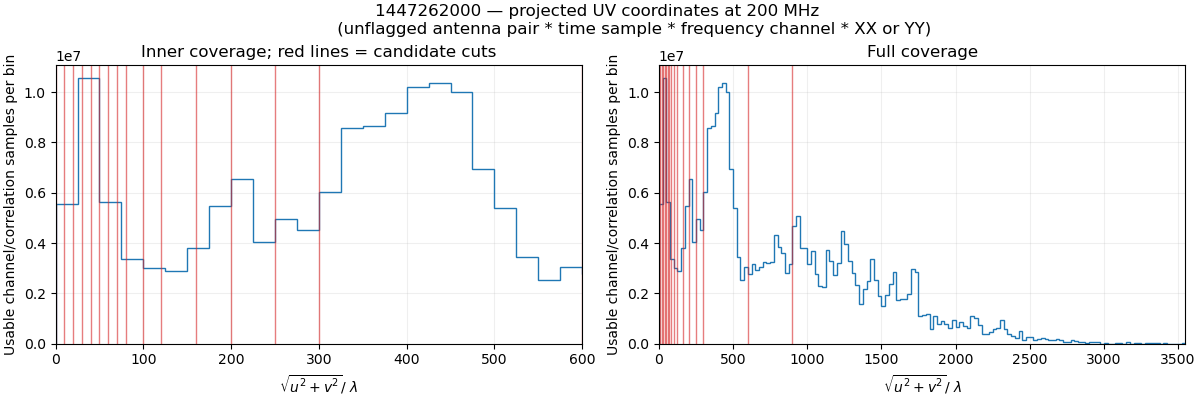

In [27]:
# \unflagged text{antenna pair} \times \text{time sample} \times \text{frequency channel} \times \text{XX or YY}.\]
bins = np.arange(0, rho.max() + bin_width, bin_width)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for ax in axes:
    ax.hist(rho, bins=bins, weights=sample_count, histtype="step", color="tab:blue")
    for cut in uvmin_choices:
        ax.axvline(cut, color="tab:red", alpha=0.6, linewidth=1)
    ax.set_xlabel("$\sqrt{u^2+v^2} / ~\lambda$")
    ax.set_ylabel("Usable channel/correlation samples per bin")
    ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
    ax.grid(alpha=0.2)
axes[0].set_xlim(0, zoom_max)
# axes[0].set_xscale("log")
axes[0].set_title("Inner coverage; red lines = candidate cuts")
# axes[1].set_xscale("log")
axes[1].set_xlim(0, bins[-1])
axes[1].set_title("Full coverage")
fig.suptitle(title)
fig.savefig(output_dir / "uv_radial_histogram.png", dpi=160)
plt.show()


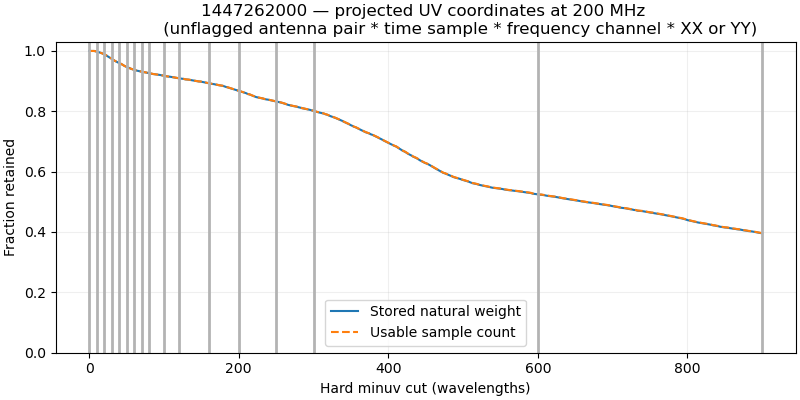

minuv   retained weight   retained samples   ideal noise factor
    0         1.000              1.000              1.000
   10         0.998              0.998              1.001
   20         0.989              0.989              1.006
   30         0.974              0.974              1.013
   40         0.960              0.960              1.021
   50         0.947              0.947              1.028
   60         0.937              0.937              1.033
   70         0.931              0.931              1.036
   80         0.926              0.926              1.039
  100         0.918              0.918              1.044
  120         0.909              0.909              1.049
  160         0.893              0.893              1.058
  200         0.868              0.868              1.074
  250         0.833              0.833              1.096
  300         0.802              0.802              1.117
  600         0.524              0.525              1.381
  900   

In [17]:
order = np.argsort(rho)
r_sorted = rho[order]
weight_tail = np.r_[np.cumsum(natural_weight[order][::-1])[::-1], 0.0]
count_tail = np.r_[np.cumsum(sample_count[order][::-1])[::-1], 0.0]
cuts = np.unique(np.r_[np.linspace(0, max(zoom_max, max(uvmin_choices)), 400), uvmin_choices])
indices = np.searchsorted(r_sorted, cuts, side="left")
weight_fraction = weight_tail[indices] / weight_tail[0]
count_fraction = count_tail[indices] / count_tail[0]

fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
ax.plot(cuts, weight_fraction, label="Stored natural weight")
ax.plot(cuts, count_fraction, "--", label="Usable sample count")
for cut in uvmin_choices:
    ax.axvline(cut, color="0.7", linewidth=2)
ax.set(xlabel="Hard minuv cut (wavelengths)", ylabel="Fraction retained",
       ylim=(0, 1.03), title=title)
ax.legend()
ax.grid(alpha=0.2)
fig.savefig(output_dir / "uv_retained_fraction.png", dpi=160)
plt.show()

print("minuv   retained weight   retained samples   ideal noise factor")
for cut in uvmin_choices:
    k = np.searchsorted(r_sorted, cut, side="left")
    fw, fn = weight_tail[k]/weight_tail[0], count_tail[k]/count_tail[0]
    noise_factor = 1/np.sqrt(fw) if fw > 0 else np.inf
    print(f"{cut:5g}       {fw:7.3f}            {fn:7.3f}              {noise_factor:.3f}")
np.savetxt(output_dir / "uv_retained_fraction.csv",
           np.column_stack((cuts, weight_fraction, count_fraction)), delimiter=",",
           header="minuv_lambda,natural_weight_fraction,sample_fraction", comments="")


## 5. 2-D UV sampling density

The (-u,-v) conjugate is included for display with half the weight on each side, so the total count is unchanged. Colour is logarithmic. The two panels use different cell sizes and independent colour scales: compare geometry, not their absolute colours. These display bins are not WSClean's imaging-weight grid.


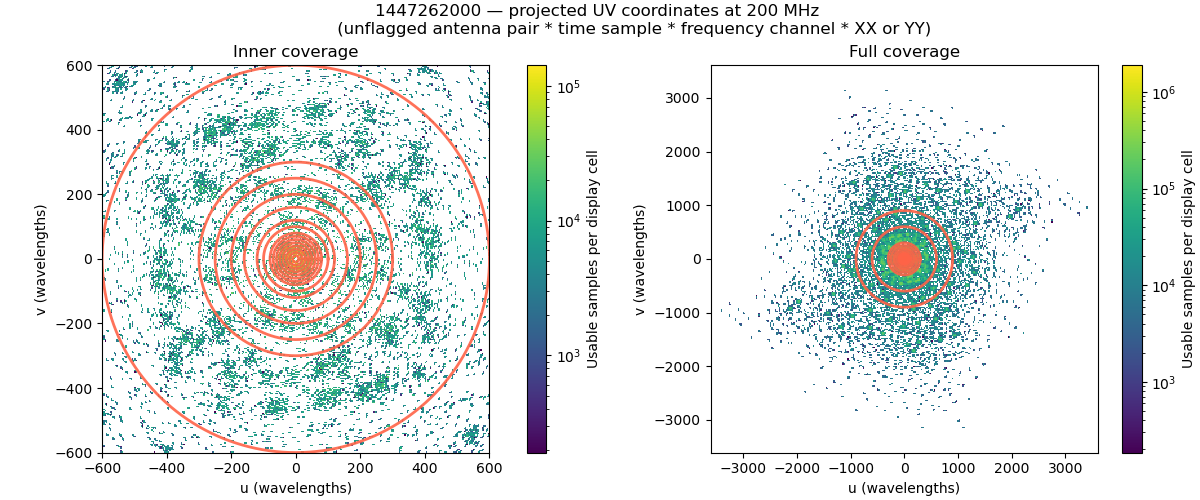

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
u_display = np.r_[u, -u]
v_display = np.r_[v, -v]
counts_display = np.r_[sample_count, sample_count] / 2
angle = np.linspace(0, 2*np.pi, 361)
for ax, limit, label in zip(axes, [zoom_max, rho.max()*1.02], ["Inner coverage", "Full coverage"]):
    edges = np.linspace(-limit, limit, 301)
    density, _, _ = np.histogram2d(u_display, v_display, bins=(edges, edges),
                                  weights=counts_display)
    masked = np.ma.masked_less_equal(density.T, 0)
    mesh = ax.pcolormesh(edges, edges, masked, norm=LogNorm(), cmap="viridis", shading="auto")
    for cut in uvmin_choices:
        ax.plot(cut*np.cos(angle), cut*np.sin(angle), color="tomato", alpha=0.9, linewidth=2)
    ax.set(xlabel="u (wavelengths)", ylabel="v (wavelengths)", title=label,
           xlim=(-limit, limit), ylim=(-limit, limit), aspect="equal")
    fig.colorbar(mesh, ax=ax, label="Usable samples per display cell")
fig.suptitle(title)
fig.savefig(output_dir / "uv_density_2d.png", dpi=160)
plt.show()


## How to use these plots

- Locate concentrations and gaps relative to 50, 100, 300, 600 and 900 wavelengths.
- Check whether a proposed cut removes a large fraction of usable weight.
- Inspect directional gaps; a radial histogram hides them.
- Choose promising cuts using these diagnostics **together with** your image RMS, reliable detections, target S/N and PSF/ringing inspection.
- A common array layout does not guarantee identical coverage after receiver flags and projection.
- This notebook does not calculate Briggs weights. Briggs uses local **2-D UV-cell density**, not radial histogram counts; reproducing WSClean also requires its imaging grid and frequency-weighting settings.

Background: [WSClean image weighting](https://wsclean.readthedocs.io/en/latest/image_weighting.html), [tapering](https://wsclean.readthedocs.io/en/latest/tapering.html), [python-casacore table API](https://casacore.github.io/python-casacore/casacore_tables.html).


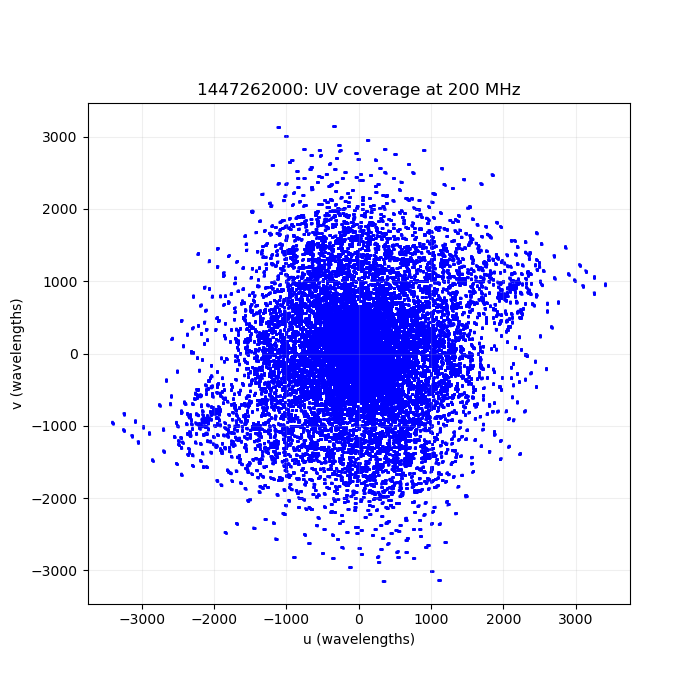

In [19]:
fig, ax = plt.subplots(figsize=(7, 7))

ax.scatter(u, v, s=1, color="blue", alpha=0.1)
ax.scatter(-u, -v, s=1, color="blue", alpha=0.1)

ax.set(
    xlabel="u (wavelengths)",
    ylabel="v (wavelengths)",
    title=f"{obsnum}: UV coverage at {reference_mhz:g} MHz",
    aspect="equal",
)
ax.grid(alpha=0.2)
plt.show()

In [20]:
#

# Inspect Briggs 

In [21]:
# Uses u, v and natural_weight from the previous notebook.

robust_choices = [-2, -1.5, -1, -0.5, 0, 0.5]
robust_choices = [-0.4,-0.3,-0.2,-0.1,0,0.1,0.2,0.3,0.4]
minuv = 100                  # Fixed for this comparison
grid_size = 513              # Odd size puts UV origin at central pixel

# Select usable measurements and include conjugate coordinates.
keep = np.hypot(u, v) >= minuv
usable_tiles.update(a1[keep].tolist())
usable_tiles.update(a2[keep].tolist())

uu = np.r_[u[keep], -u[keep]]
vv = np.r_[v[keep], -v[keep]]
ww = np.r_[natural_weight[keep], natural_weight[keep]] / 2

if len(ww) == 0:
    raise ValueError("No samples remain after the minuv cut.")

# Symmetric UV grid.
limit = max(np.abs(uu).max(), np.abs(vv).max()) * 1.05
edges = np.linspace(-limit, limit, grid_size + 1)
centres = (edges[:-1] + edges[1:]) / 2
du = edges[1] - edges[0]

# W = total natural weight in each UV cell.
W, _, _ = np.histogram2d(uu, vv, bins=(edges, edges), weights=ww)
U, V = np.meshgrid(centres, centres, indexing="ij")
grid_radius = np.hypot(U, V)

# Standard Briggs normalization.
density_scale = np.sum(W**2) / np.sum(W)

briggs_grids = []
for robust in robust_choices:
    f_squared = (5 * 10**(-robust))**2 / density_scale
    weighted_grid = W / (1 + f_squared * W)

    # Normalize so every map has total weight = 1.
    weighted_grid /= weighted_grid.sum()
    briggs_grids.append(weighted_grid)

print(f"Illustrative UV cell width: {du:.1f} wavelengths")

Illustrative UV cell width: 14.0 wavelengths


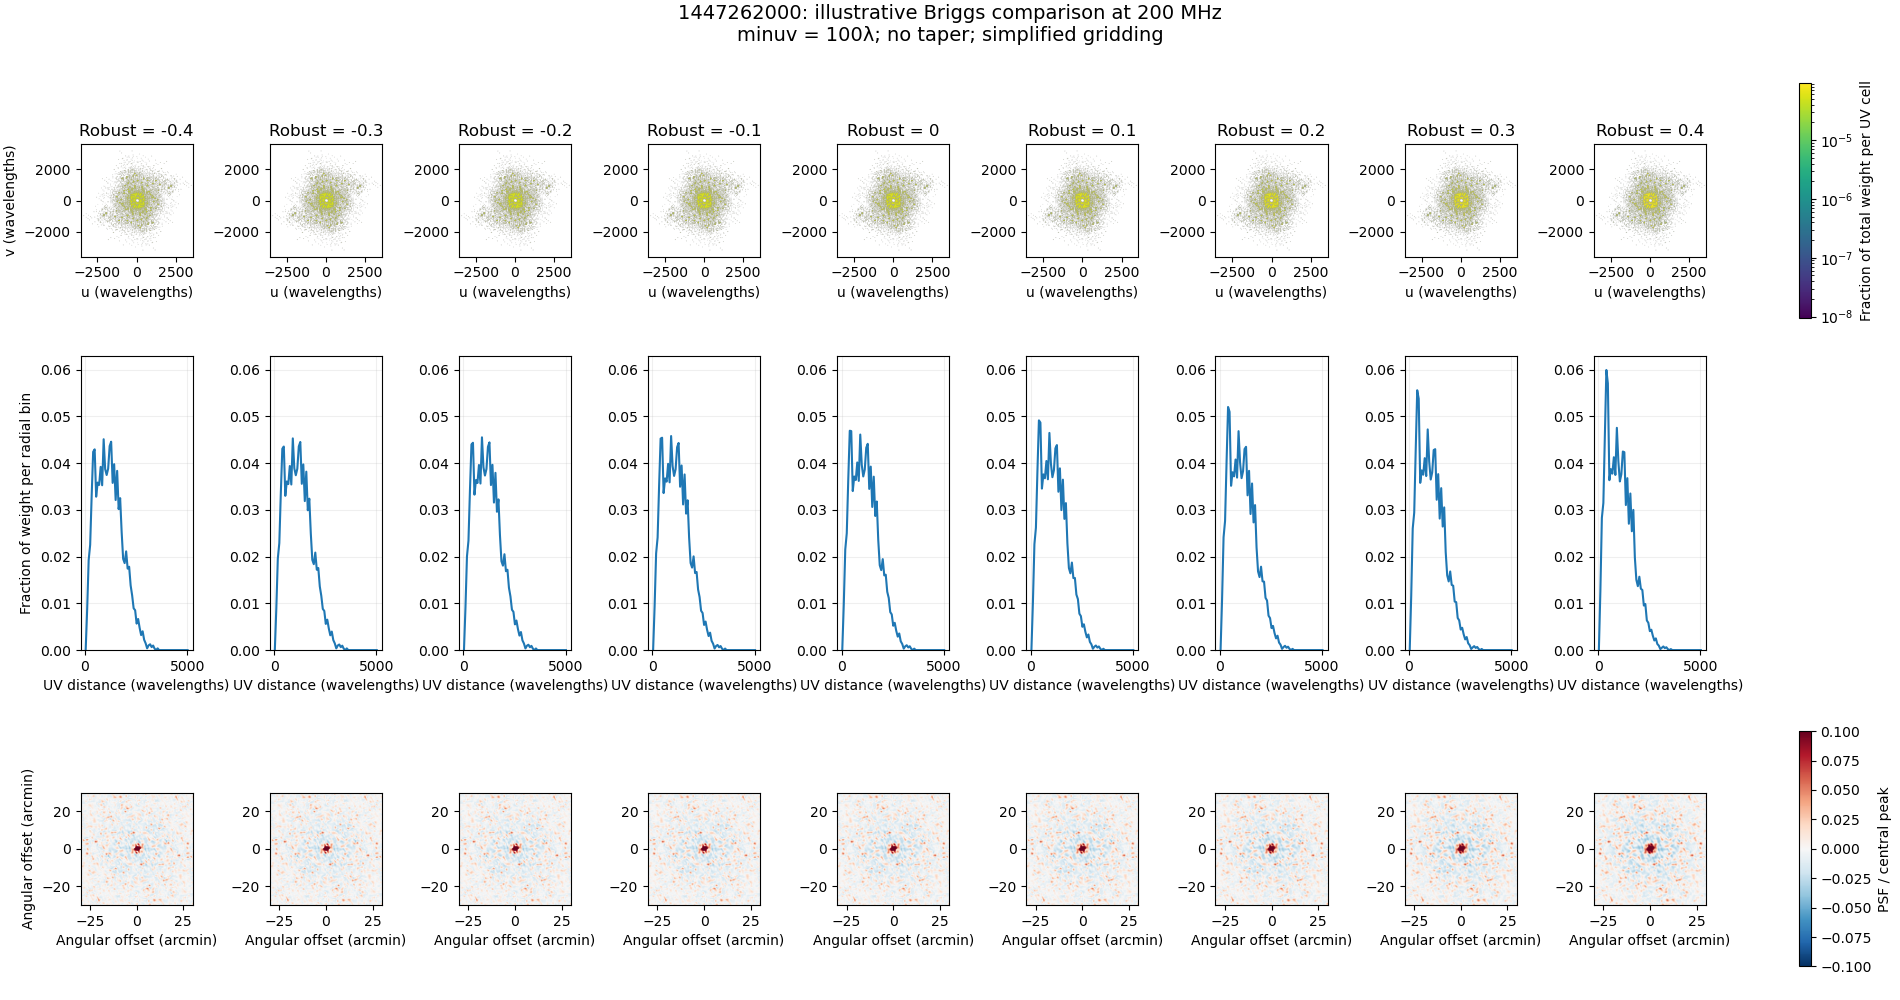

In [22]:
from matplotlib.colors import LogNorm

fig, axes = plt.subplots(
    3, len(robust_choices),
    figsize=(19, 10),
    constrained_layout=True,
)

# Common colour scale for all UV-weight panels.
maximum = max(grid.max() for grid in briggs_grids)
weight_norm = LogNorm(vmin=maximum * 1e-4, vmax=maximum)

radial_bins = np.linspace(0, grid_radius.max(), 70)
radial_centres = (radial_bins[:-1] + radial_bins[1:]) / 2

# Fourier-conjugate angular coordinates, in arcminutes.
angle = np.fft.fftshift(np.fft.fftfreq(grid_size, d=du))
angle *= 180 / np.pi * 60
dangle = angle[1] - angle[0]
image_extent = [
    angle[0] - dangle / 2, angle[-1] + dangle / 2,
    angle[0] - dangle / 2, angle[-1] + dangle / 2,
]

psf_zoom_arcmin = 30

for column, (robust, grid) in enumerate(
    zip(robust_choices, briggs_grids)
):
    # Row 1: normalized weight in each UV cell.
    ax = axes[0, column]
    uv_plot = ax.imshow(
        np.ma.masked_less_equal(grid.T, 0),
        origin="lower",
        extent=[-limit, limit, -limit, limit],
        norm=weight_norm,
        cmap="viridis",
        aspect="equal",
    )
    ax.set_title(f"Robust = {robust:g}")
    ax.set_xlabel("u (wavelengths)")

    # Row 2: fraction of total imaging weight in each radial bin.
    radial_weight, _ = np.histogram(
        grid_radius.ravel(),
        bins=radial_bins,
        weights=grid.ravel(),
    )
    axes[1, column].plot(radial_centres, radial_weight)
    axes[1, column].set_xlabel("UV distance (wavelengths)")
    axes[1, column].grid(alpha=0.2)

    # Row 3: approximate dirty PSF = Fourier transform of weights.
    psf = np.fft.fftshift(
        np.fft.ifft2(np.fft.ifftshift(grid))
    ).real
    psf /= psf[grid_size // 2, grid_size // 2]

    psf_plot = axes[2, column].imshow(
        psf.T,
        origin="lower",
        extent=image_extent,
        cmap="RdBu_r",
        vmin=-0.1,
        vmax=0.1,
        aspect="equal",
    )
    axes[2, column].set_xlim(-psf_zoom_arcmin, psf_zoom_arcmin)
    axes[2, column].set_ylim(-psf_zoom_arcmin, psf_zoom_arcmin)
    axes[2, column].set_xlabel("Angular offset (arcmin)")

# Same y scale across all radial profiles.
radial_ymax = max(ax.get_ylim()[1] for ax in axes[1])
for ax in axes[1]:
    ax.set_ylim(0, radial_ymax)

axes[0, 0].set_ylabel("v (wavelengths)")
axes[1, 0].set_ylabel("Fraction of weight per radial bin")
axes[2, 0].set_ylabel("Angular offset (arcmin)")

fig.colorbar(
    uv_plot, ax=list(axes[0]),
    label="Fraction of total weight per UV cell",
    shrink=0.8,
)
fig.colorbar(
    psf_plot, ax=list(axes[2]),
    label="PSF / central peak",
    shrink=0.8,
)

fig.suptitle(
    f"{obsnum}: illustrative Briggs comparison at {reference_mhz:g} MHz\n"
    f"minuv = {minuv}λ; no taper; simplified gridding",
    fontsize=14,
)

fig.savefig(output_dir / "briggs_illustration.png", dpi=160)
plt.show()